# Eksplorasi Data & Tahapan Preprocessing — Segmentasi Parasit Malaria

Notebook ini dibagi dua bagian besar:

1. **Data dulu, semuanya**: 32 crop parasit dari `malaria_images/` ditampilkan satu per satu dalam grid, tabel metadata, distribusi luas parasit, dan histogram warna;
2. **Preprocessing**: tahapan yang diuji pada bagian data yang sama (Lab b, koreksi background, median, CLAHE, Reinhard), masing-masing dengan visualisasi + histogram.

Catatan istilah: malaria disebabkan **parasit** (*Plasmodium*), bukan virus. Dua dimensi label: **spesies** (*P. falciparum* / *P. vivax*) dan **stadium** (ring → trophozoite → schizont → gametocyte).

In [1]:
from pathlib import Path
import json, base64, zlib, io, warnings

import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from skimage.filters import threshold_multiotsu
from skimage.morphology import remove_small_objects, disk

warnings.filterwarnings('ignore')
%matplotlib inline
cv2.setRNGSeed(42)

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / 'mp-idb-DatasetNinja').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
    if PROJECT_ROOT == Path('/'):
        raise FileNotFoundError('Root proyek tidak ditemukan')

CROPS_DIR = PROJECT_ROOT / 'malaria_images'
ANN_DIR = PROJECT_ROOT / 'mp-idb-DatasetNinja' / 'ds' / 'ann'
RESULTS_DIR = PROJECT_ROOT / 'results' / 'data_preprocessing'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PAD = 80
MIN_AREA = 12
print('Crops:', CROPS_DIR, '|', len(list(CROPS_DIR.glob('*.png'))), 'file')

Crops: /home/archian/Kuliah/Semester5/ADCB/Project/citra-segmentasi-malaria/malaria_images | 32 file


## 1. Data dulu: muat semua crop + metadata

In [2]:
meta = pd.read_csv(CROPS_DIR / 'metadata.csv')
display(meta)

_mask_cache = {}
def load_gt_mask(source_image, bbox):
    if source_image not in _mask_cache:
        ann = json.load(open(ANN_DIR / (source_image + '.json')))
        full = np.zeros((ann['size']['height'], ann['size']['width']), dtype=np.uint8)
        for obj in ann['objects']:
            origin = obj['bitmap']['origin']
            png = zlib.decompress(base64.b64decode(obj['bitmap']['data']))
            bm_arr = np.array(Image.open(io.BytesIO(png)))
            bm = (bm_arr[..., -1] if bm_arr.ndim == 3 else bm_arr) > 0
            h, w = bm.shape
            full[origin[1]:origin[1]+h, origin[0]:origin[0]+w] |= bm.astype(np.uint8)
        _mask_cache[source_image] = full
    x, y, w, h = int(bbox.bbox_x), int(bbox.bbox_y), int(bbox.bbox_w), int(bbox.bbox_h)
    return _mask_cache[source_image][max(0,y-PAD):y+h+PAD, max(0,x-PAD):x+w+PAD].astype(bool)

crops, gts = [], []
for _, r in meta.iterrows():
    img = cv2.cvtColor(cv2.imread(str(CROPS_DIR / r.filename), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    crops.append(img); gts.append(load_gt_mask(r.source_image, r))
print(f'{len(crops)} crop + mask GT dimuat')

,filename,species,stage,source_image,parasite_area_px,bbox_x,bbox_y,bbox_w,bbox_h,crop_size
0,falciparum_ring_1.png,falciparum,ring stage,1408161544-0001-S_R.jpg,22930,1009,578,187,163,347x323
1,falciparum_ring_2.png,falciparum,ring stage,1305121398-0019-R.jpg,20406,1088,969,164,154,324x314
2,falciparum_ring_3.png,falciparum,ring stage,1408161544-0002-R_S.jpg,18669,1218,640,160,156,320x316
3,falciparum_ring_4.png,falciparum,ring stage,1408161544-0003-R_S.jpg,16979,1030,677,148,146,308x306
4,falciparum_trophozoite_1.png,falciparum,trophozoite stage,1701151546-0015-R_T.jpg,12473,356,326,145,120,305x280
5,falciparum_trophozoite_2.png,falciparum,trophozoite stage,1603223711-0002-T_G.jpg,11425,1343,1010,192,107,352x267
6,falciparum_trophozoite_3.png,falciparum,trophozoite stage,1704282807-0021-T_G_R.jpg,11169,1220,732,82,194,242x354
7,falciparum_trophozoite_4.png,falciparum,trophozoite stage,1704282807-0013-R_T.jpg,9049,1314,761,112,104,272x264
8,falciparum_schizont_1.png,falciparum,schizont stage,1408161544-0001-S_R.jpg,22930,1009,578,187,163,347x323
9,falciparum_schizont_2.png,falciparum,schizont stage,1408161544-0002-R_S.jpg,18669,1218,640,160,156,320x316


32 crop + mask GT dimuat


## 2. Visualisasi: semua crop dalam grid per spesies dan stadium

Tiap baris = satu stadium, blok kiri = *P. falciparum*, kanan = *P. vivax*. Gambar merah muda adalah bingkai crop.

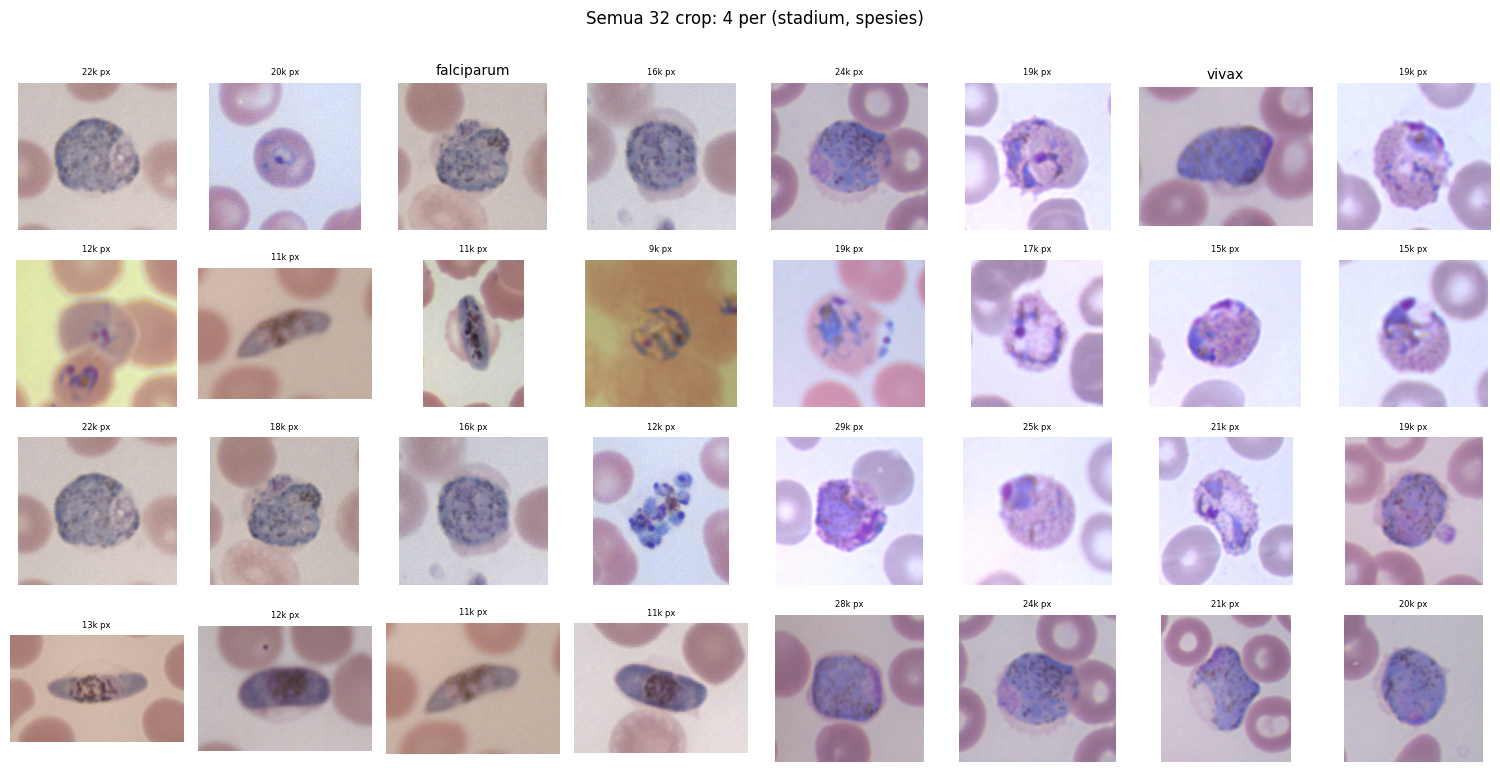

In [3]:
stages = ['ring stage', 'trophozoite stage', 'schizont stage', 'gametocyte stage']
species = ['falciparum', 'vivax']

per_group = int(meta.groupby(['species', 'stage']).size().max())
fig, axes = plt.subplots(len(stages), 2 * per_group,
                         figsize=(1.9 * per_group, 1.9 * len(stages)) * np.array([2, 1]))
for i, st in enumerate(stages):
    for j, sp in enumerate(species):
        rows = meta[(meta.stage == st) & (meta.species == sp)].sort_values('filename')
        for k, (_, r) in enumerate(rows.iterrows()):
            idx = int(meta.index[meta.filename == r.filename][0])
            ax = axes[i, j * per_group + k]
            ax.imshow(crops[idx])
            ax.set_title(f'{r.parasite_area_px//1000}k px', fontsize=6)
for ax in axes.ravel():
    ax.axis('off')
for i, st in enumerate(stages):
    axes[i, 0].set_ylabel(st.replace(' stage', ''), fontsize=9)
for j, sp in enumerate(species):
    axes[0, j * per_group + per_group // 2].set_title(sp, fontsize=10)
plt.suptitle(f'Semua {len(meta)} crop: {per_group} per (stadium, spesies)', y=1.01)
plt.tight_layout(); plt.show()

## 3. Statistik data: luas parasit dan histogram warna

Luas parasit (dari metadata) dulu, lalu histogram rata-rata kanal RGB per spesies untuk melihat karakter pewarnaan Giemsa.

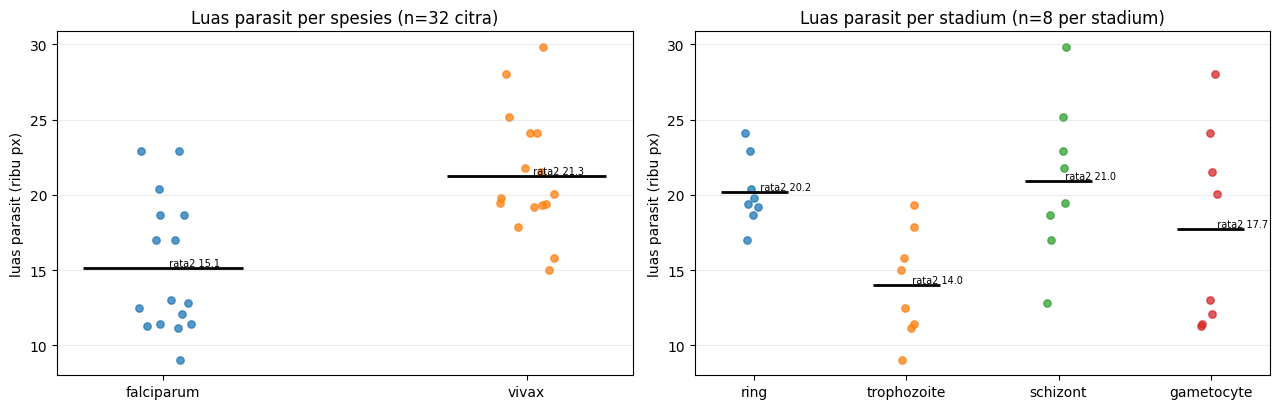

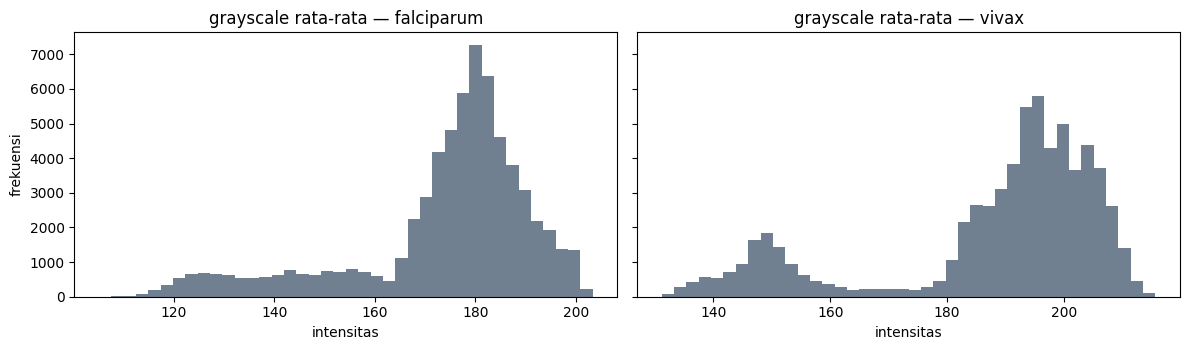

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
rng = np.random.default_rng(42)
meta2 = meta.copy(); meta2['area_k'] = meta2.parasite_area_px / 1000
for ax, col in zip(axes, ['species', 'stage']):
    cats = list(meta2[col].unique())
    for i, c in enumerate(cats):
        vals = meta2.loc[meta2[col] == c, 'area_k'].to_numpy()
        ax.scatter(np.full(len(vals), i) + rng.uniform(-0.08, 0.08, len(vals)), vals,
                   s=28, alpha=0.75, label=None)
        ax.hlines(vals.mean(), i - 0.22, i + 0.22, color='black', lw=2)
        ax.text(i, vals.mean(), f'  rata2 {vals.mean():.1f}', va='bottom', fontsize=7)
    ax.set_xticks(range(len(cats)))
    ax.set_xticklabels([str(c).replace(' stage', '') for c in cats])
    ax.set_ylabel('luas parasit (ribu px)')
    ax.grid(axis='y', alpha=0.25)
axes[0].set_title(f'Luas parasit per spesies (n={len(meta2)} citra)')
axes[1].set_title('Luas parasit per stadium (n=8 per stadium)')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, sp in zip(axes, species):
    idxs = [i for i, (_, r) in enumerate(meta.iterrows()) if r.species == sp]
    stack = np.stack([
        cv2.resize(cv2.cvtColor(crops[i], cv2.COLOR_RGB2GRAY), (256, 256)).ravel()
        for i in idxs])
    ax.hist(stack.mean(axis=0), bins=40, color='slategray')
    ax.set_title(f'grayscale rata-rata — {sp}'); ax.set_xlabel('intensitas')
axes[0].set_ylabel('frekuensi')
plt.tight_layout(); plt.show()

## 4. Preprocessing: tahapan dan efeknya

Tahapan yang diuji (satu per satu, kumulatif):

1. **Lab b** — konversi warna, kanal b memisahkan parasit dari latar RBC;
2. **+ koreksi background** — closing besar mengestimasi latar, dikurangi dari citra;
3. **+ median filter** — meredam noise grain tanpa menggeser tepi;
4. **+ CLAHE** — penajaman kontras (kontrol);
5. **+ Reinhard** — normalisasi warna pewarnaan ke referensi dataset (alternatif).

Contoh pertama ditampilkan lengkap per tahap dengan histogram; dua contoh lain ikut sebagai pembanding visual.

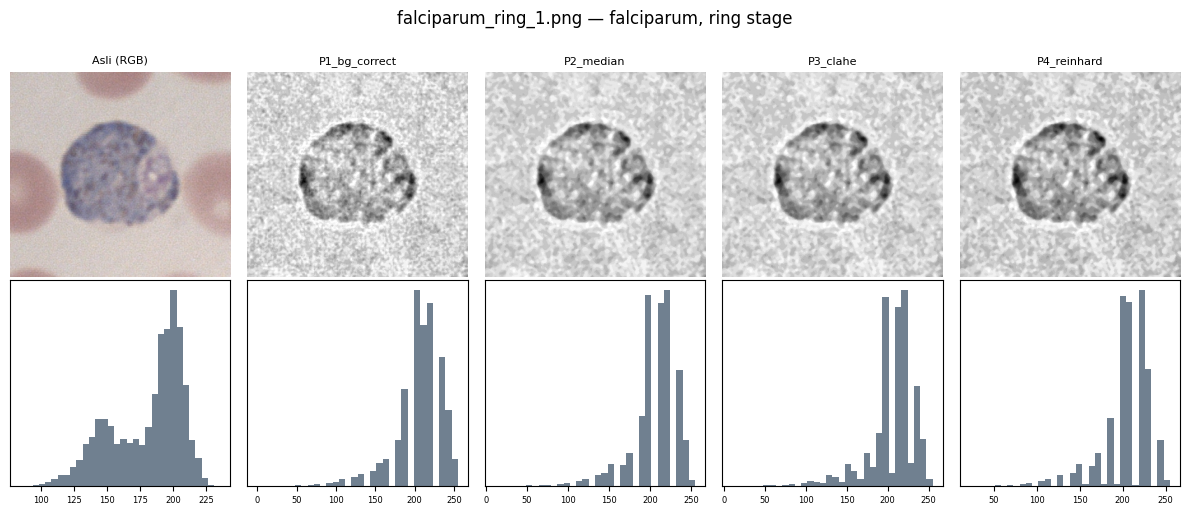

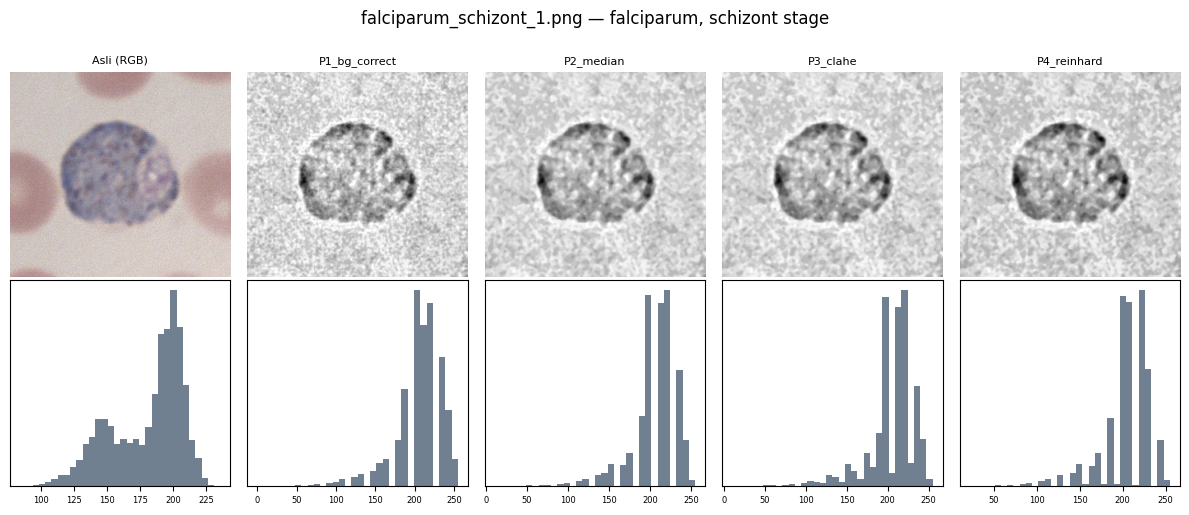

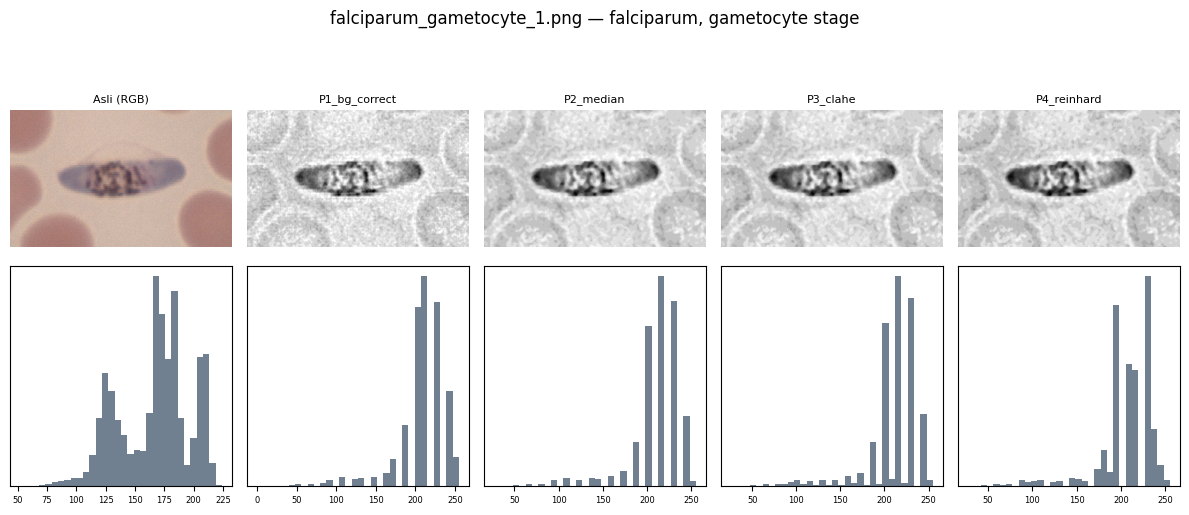

In [5]:
def lab_b(img): return cv2.cvtColor(img, cv2.COLOR_RGB2LAB)[:, :, 2]
def bg_correct(chan, r=25):
    bg = cv2.morphologyEx(chan, cv2.MORPH_CLOSE, disk(r).astype(np.uint8))
    out = cv2.subtract(chan.astype(np.int16), bg.astype(np.int16))
    return cv2.normalize(out, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
def median_f(chan, k=5): return cv2.medianBlur(chan, k)
def clahe_f(chan):
    return cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(chan)

_labs = [cv2.cvtColor(img, cv2.COLOR_RGB2LAB) for img in crops]
REF_MEAN = np.concatenate([l.reshape(-1, 3) for l in _labs]).mean(axis=0)
REF_STD = np.concatenate([l.reshape(-1, 3) for l in _labs]).std(axis=0) + 1e-6
def reinhard(img):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB).astype(np.float64)
    lab = (lab - lab.reshape(-1,3).mean(0)) / (lab.reshape(-1,3).std(0) + 1e-6) * REF_STD + REF_MEAN
    return cv2.cvtColor(np.clip(lab, 0, 255).astype(np.uint8), cv2.COLOR_LAB2RGB)

PIPELINES = {
    'P0_Lab_b': lambda img: lab_b(img),
    'P1_bg_correct': lambda img: bg_correct(lab_b(img)),
    'P2_median': lambda img: median_f(bg_correct(lab_b(img))),
    'P3_clahe': lambda img: clahe_f(median_f(bg_correct(lab_b(img)))),
    'P4_reinhard': lambda img: median_f(bg_correct(lab_b(reinhard(img)))),
}

demo_stages = ['ring stage', 'schizont stage', 'gametocyte stage']
demo_idx = [int(meta.index[(meta.stage == st) & (meta.species == 'falciparum')][0]) for st in demo_stages]
for idx in demo_idx:
    img = crops[idx]
    stages_v = [('Asli (RGB)', img)] + [(n, f(img)) for n, f in list(PIPELINES.items())[1:]]
    fig, axes = plt.subplots(2, len(stages_v), figsize=(2.4 * len(stages_v), 5))
    for j, (name, ch) in enumerate(stages_v):
        axes[0, j].imshow(ch, cmap='gray' if ch.ndim == 2 else None)
        axes[0, j].set_title(name, fontsize=8); axes[0, j].axis('off')
        axes[1, j].hist(ch.ravel(), bins=32, color='slategray'); axes[1, j].set_yticks([])
        axes[1, j].tick_params(labelsize=6)
    plt.suptitle(f'{meta.filename[idx]} — {meta.species[idx]}, {meta.stage[idx]}', y=1.02)
    plt.tight_layout(); plt.show()

## 5. Evaluasi ringkas: tiap varian preprocessing dengan segmentasi Otsu multilevel 3

Satu baris tabel = satu varian pipeline di atas seluruh 32 crop, terhadap mask ground truth.

,dice,iou
pipeline,,
P0_Lab_b,0.7029,0.5737
P1_bg_correct,0.4376,0.2867
P2_median,0.4433,0.2923
P3_clahe,0.4855,0.3299
P4_reinhard,0.4667,0.3133


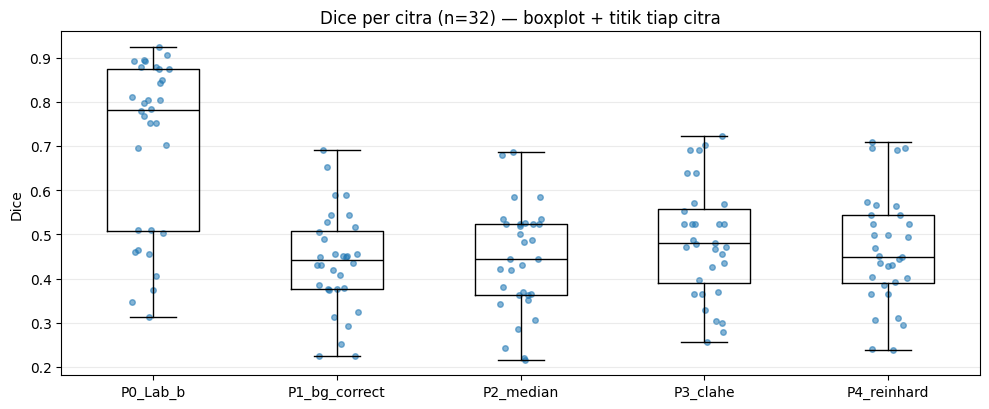

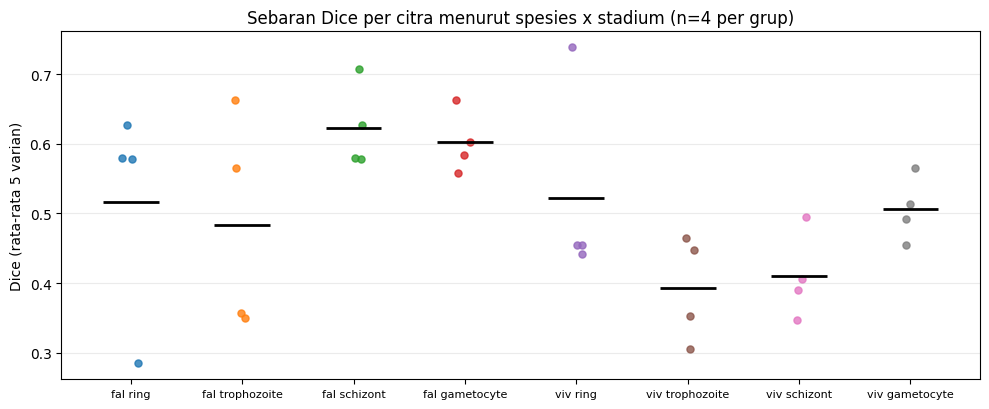

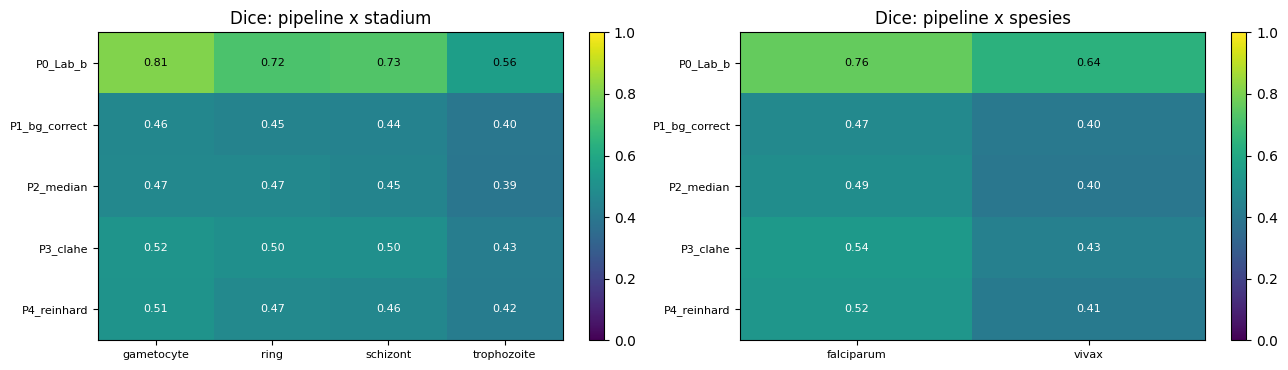

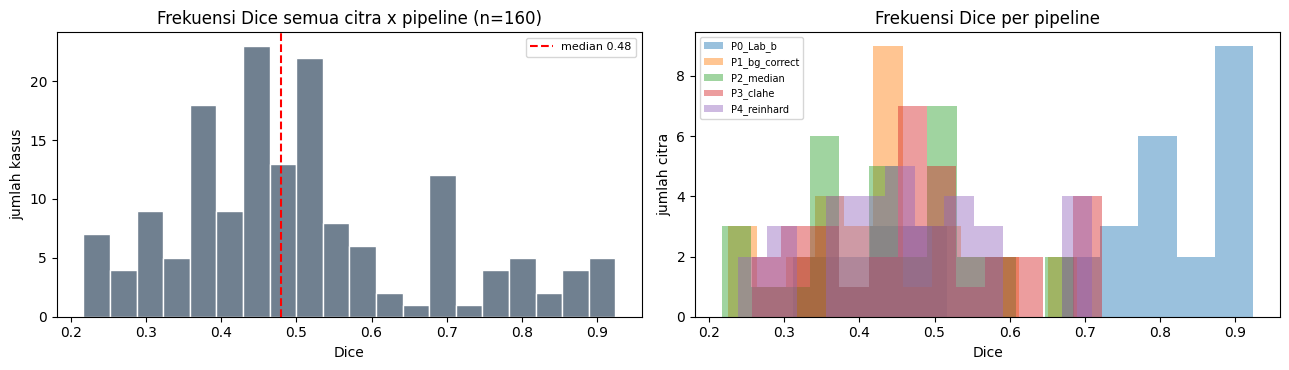

Tersimpan: /home/archian/Kuliah/Semester5/ADCB/Project/citra-segmentasi-malaria/results/data_preprocessing/summary.csv


In [6]:
def seg_otsu3(chan):
    try:
        th = threshold_multiotsu(chan, classes=3)
        mask = chan < th[0]
    except Exception:
        mask = np.zeros(chan.shape, dtype=bool)
    return remove_small_objects(mask, max_size=MIN_AREA - 1, connectivity=2)

def dice_iou(pred, gt):
    tp = np.logical_and(pred, gt).sum()
    fp = np.logical_and(pred, ~gt).sum(); fn = np.logical_and(~pred, gt).sum()
    return 2*tp/(2*tp+fp+fn+1e-9), tp/(tp+fp+fn+1e-9)

rows = []
for name, fn in PIPELINES.items():
    d = [dice_iou(seg_otsu3(fn(img)), gt) for img, gt in zip(crops, gts)]
    rows.append({'pipeline': name, 'dice': np.mean([x[0] for x in d]), 'iou': np.mean([x[1] for x in d])})
summary = pd.DataFrame(rows).set_index('pipeline').round(4)
display(summary)

per_img = {name: np.array([dice_iou(seg_otsu3(fn(img)), gt)[0] for img, gt in zip(crops, gts)])
           for name, fn in PIPELINES.items()}
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.boxplot([per_img[p] for p in PIPELINES], tick_labels=list(PIPELINES), widths=0.5,
           showfliers=False, medianprops={'color': 'black'})
for i, p in enumerate(PIPELINES, start=1):
    ax.scatter(np.full(len(per_img[p]), i) + rng.uniform(-0.12, 0.12, len(per_img[p])),
               per_img[p], s=16, alpha=0.55, color='tab:blue')
ax.set_ylabel('Dice'); ax.set_xlabel('')
ax.set_title(f'Dice per citra (n={len(crops)}) — boxplot + titik tiap citra')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout(); plt.show()

stage_order = ['ring stage', 'trophozoite stage', 'schizont stage', 'gametocyte stage']
fig, ax = plt.subplots(figsize=(10, 4.2))
for i, (sp, st) in enumerate([(sp, st) for sp in species for st in stage_order], start=1):
    m = (meta.species == sp) & (meta.stage == st)
    vals = np.mean([per_img[p][m.to_numpy()] for p in PIPELINES], axis=0)
    ax.scatter(np.full(len(vals), i) + rng.uniform(-0.08, 0.08, len(vals)), vals, s=26, alpha=0.8)
    ax.hlines(vals.mean(), i - 0.25, i + 0.25, color='black', lw=2)
ax.set_xticks(range(1, 9))
ax.set_xticklabels([f'{sp[:3]} {st.split()[0]}' for sp in species for st in stage_order], fontsize=8)
ax.set_ylabel('Dice (rata-rata 5 varian)')
ax.set_title('Sebaran Dice per citra menurut spesies x stadium (n=4 per grup)')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout(); plt.show()

# Heatmap Dice: pipeline x stadium, dan pipeline x spesies
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, col, ttl in [(axes[0], 'stage', 'Dice: pipeline x stadium'),
                     (axes[1], 'species', 'Dice: pipeline x spesies')]:
    mat = np.array([[per_img[p][(meta[col] == c).to_numpy()].mean() for c in sorted(meta[col].unique())]
                    for p in PIPELINES])
    im = ax.imshow(mat, cmap='viridis', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(mat.shape[1]))
    ax.set_xticklabels([c.replace(' stage', '') for c in sorted(meta[col].unique())], fontsize=8)
    ax.set_yticks(range(mat.shape[0])); ax.set_yticklabels(list(PIPELINES), fontsize=8)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, f'{mat[i, j]:.2f}', ha='center', va='center',
                    color='white' if mat[i, j] < 0.55 else 'black', fontsize=8)
    ax.set_title(ttl); plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

# Histogram frekuensi Dice: gabungan semua citra & pipeline + per pipeline
all_dice = np.concatenate([per_img[p] for p in PIPELINES])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(all_dice, bins=20, color='slategray', edgecolor='white')
axes[0].axvline(np.median(all_dice), color='red', ls='--', label=f'median {np.median(all_dice):.2f}')
axes[0].set_title(f'Frekuensi Dice semua citra x pipeline (n={len(all_dice)})')
axes[0].set_xlabel('Dice'); axes[0].set_ylabel('jumlah kasus'); axes[0].legend(fontsize=8)
for p in PIPELINES:
    axes[1].hist(per_img[p], bins=12, alpha=0.45, label=p)
axes[1].set_title('Frekuensi Dice per pipeline'); axes[1].set_xlabel('Dice')
axes[1].set_ylabel('jumlah citra'); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

summary.to_csv(RESULTS_DIR / 'summary.csv')
print('Tersimpan:', RESULTS_DIR / 'summary.csv')

## 6. Kesimpulan

- Pada crop terpusat, **Lab b saja sudah paling baik** (Dice ~0.68); tahap tambahan (koreksi background, median, CLAHE, Reinhard) justru menurunkan Dice karena memangkas recall parasit yang tipis.
- Koreksi background lebih relevan untuk **citra penuh** (lihat notebook Progress 1), bukan untuk crop.
- Visual + histogram per tahap di Bagian 4 menunjukkan kenapa: tiap tahap menggeser distribusi intensitas, dan tahap yang menipiskan objek kecil paling merugikan ring.